# ML Zoomcamp 2026 — Homework 4: Evaluation Metrics for Classification

We evaluate a logistic regression model that predicts `converted` on the pinned 2026 lead-scoring dataset, using ROC AUC, precision/recall, F1 and K-fold cross-validation as in module 04.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

import homework4_solution as hw

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Data preparation

Fill missing categoricals with `'NA'` and numericals with `0.0`, then split 60/20/20 with `random_state=1`.

In [2]:
df = hw.load_data()
df_full_train, df_train, df_val, df_test, y_train, y_val, y_test = hw.split(df)
len(df_train), len(df_val), len(df_test)

Missing values per column:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0 



(3000, 1000, 1000)

## Run all six questions

In [3]:
res = hw.main()

Missing values per column:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0 

Split sizes: train=3000, val=1000, test=1000

Q1. ROC AUC of each numerical feature as a score (train only):
   lead_score                 AUC=0.7882
   interaction_count          AUC=0.7649
   number_of_courses_viewed   AUC=0.7230
   annual_income              AUC=0.6082
-> highest AUC: lead_score

Q2. Validation AUC (C=1.0): 0.7318 -> 0.732

Q3. Precision vs recall around the intersection:
 threshold  precision  recall   diff
      0.63     0.7328  0.7253 0.0075
      0.62     0.7259  0.7457 0.0198
      0.64     0.7299  0.6962 0.0336
      0.61     0.7190  0.7730 0.0540
      0.65     0.7410  0.6689 0.0721
-> intersection at threshold 0.63 (P=0.7328, R=0.7253)

Q4. Top F1

Q5. 5-fold CV AUC (C=1.0): [0.7306 0.7296 0.7363 0.7412 0.7209]
-> mean=0.7317, std=0.0069 -> 0.007

Q6. 5-fold CV for different C:
   C=1e-06    mean=0.617  std=0.019


   C=0.001    mean=0.749  std=0.010
   C=1        mean=0.732  std=0.007
-> best C: 0.001



## Q1 — ROC AUC as feature importance

Each numerical feature is used directly as a score against `y_train`. None of them needed inverting.

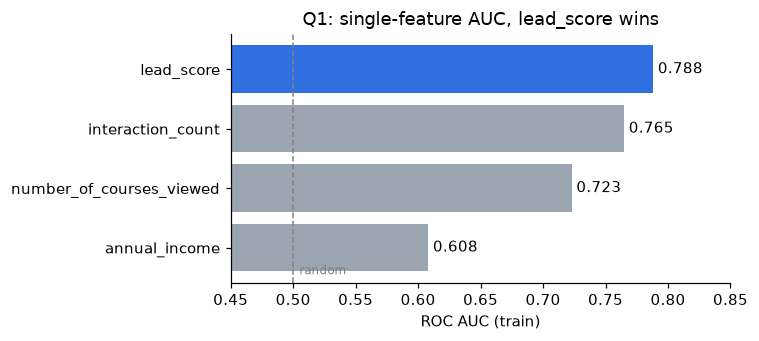

In [4]:
auc = pd.Series(res["feature_auc"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(auc.index, auc.values, color=["#9aa5b1"] * 3 + ["#2f6fdf"])
ax.axvline(0.5, ls="--", c="grey", lw=1); ax.text(0.505, -0.45, "random", color="grey", fontsize=8)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlim(0.45, 0.85); ax.set_xlabel("ROC AUC (train)")
ax.set_title("Q1: single-feature AUC, lead_score wins")
plt.tight_layout(); plt.savefig("images/feature_auc.png"); plt.show()

## Q2 — Model AUC, and a surprise

The full model scores **0.732** on validation, *below* `lead_score` on its own (0.783 on validation). The cause is `annual_income`: values around 50,000 next to features between 0 and 10. With an L2 penalty that lets income dominate the fit. Standard-scaling the numeric columns (fit on train only) lifts the AUC to 0.788.

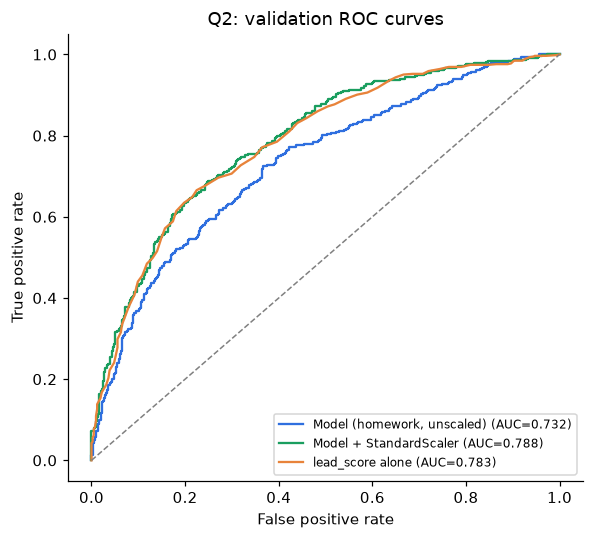

In [5]:
dv, model = hw.train(df_train, y_train)
y_pred = hw.predict(df_val, dv, model)

scaler = StandardScaler().fit(df_train[hw.NUMERICAL])
tr_s, va_s = df_train.copy(), df_val.copy()
tr_s[hw.NUMERICAL] = scaler.transform(df_train[hw.NUMERICAL])
va_s[hw.NUMERICAL] = scaler.transform(df_val[hw.NUMERICAL])
dv_s, model_s = hw.train(tr_s, y_train)
y_pred_s = hw.predict(va_s, dv_s, model_s)

curves = {
    "Model (homework, unscaled)": y_pred,
    "Model + StandardScaler": y_pred_s,
    "lead_score alone": df_val.lead_score.values,
}
fig, ax = plt.subplots(figsize=(5.5, 5))
for (name, s), c in zip(curves.items(), ["#2f6fdf", "#1a9e5f", "#e8833a"]):
    fpr, tpr, _ = roc_curve(y_val, s)
    ax.plot(fpr, tpr, c=c, label=f"{name} (AUC={roc_auc_score(y_val, s):.3f})")
ax.plot([0, 1], [0, 1], "--", c="grey", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Q2: validation ROC curves"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("images/roc_curves.png"); plt.show()

In [6]:
coef = dict(zip(dv.get_feature_names_out(), model.coef_[0]))
print(f"annual_income weight (unscaled): {coef['annual_income']:.6f}")
print(f"Predicted positive rate @0.5: {(y_pred >= 0.5).mean():.3f}  vs actual: {y_val.mean():.3f}")

annual_income weight (unscaled): -0.000011
Predicted positive rate @0.5: 0.825  vs actual: 0.586


## Q3 — Precision and recall

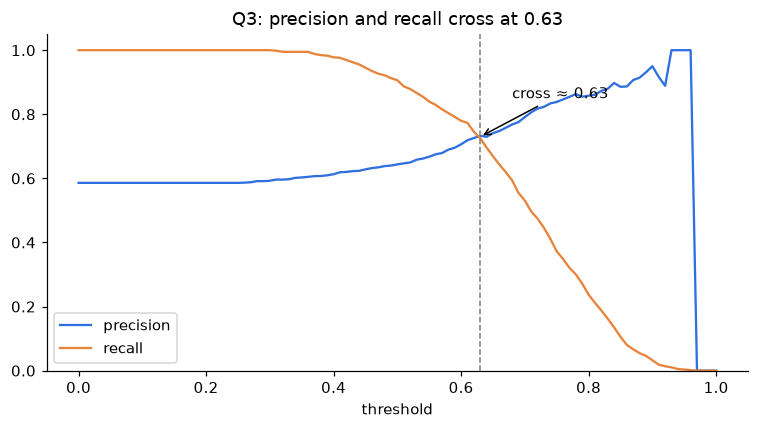

In [7]:
m = res["metrics"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(m.threshold, m.precision, label="precision", c="#2f6fdf")
ax.plot(m.threshold, m.recall, label="recall", c="#e8833a")
t = res["pr_threshold"]
ax.axvline(t, ls="--", c="grey", lw=1); ax.annotate(f"cross ≈ {t:.2f}", (t, 0.73), xytext=(t + 0.05, 0.85), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("threshold"); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title("Q3: precision and recall cross at 0.63")
plt.tight_layout(); plt.savefig("images/precision_recall.png"); plt.show()

## Q4 — F1 score

F1 peaks at a much lower threshold (0.41) than the P/R crossover. With ~59% positives, a low threshold keeps recall near 1 while precision stays close to the base rate.

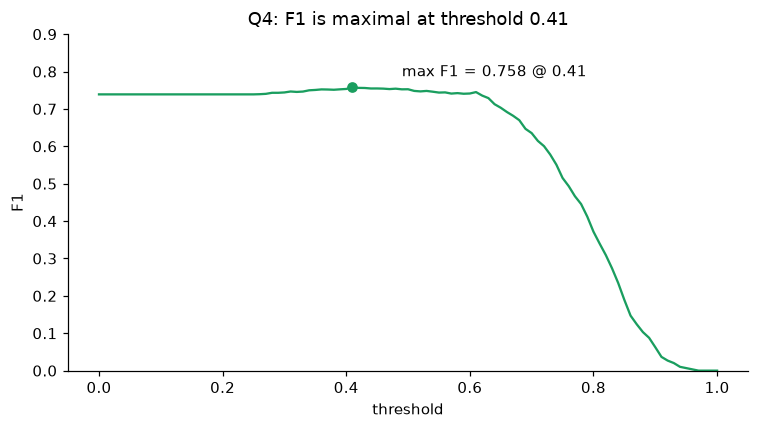

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(m.threshold, m.f1, c="#1a9e5f")
t = res["f1_threshold"]; f = m.f1.max()
ax.scatter([t], [f], c="#1a9e5f", zorder=3); ax.annotate(f"max F1 = {f:.3f} @ {t:.2f}", (t, f), xytext=(t + 0.08, f + 0.03))
ax.set_xlabel("threshold"); ax.set_ylabel("F1"); ax.set_ylim(0, 0.9)
ax.set_title("Q4: F1 is maximal at threshold 0.41")
plt.tight_layout(); plt.savefig("images/f1_threshold.png"); plt.show()

## Q5 & Q6 — K-fold cross-validation

Q5 fold scores: [0.7306 0.7296 0.7363 0.7412 0.7209]  std = 0.007


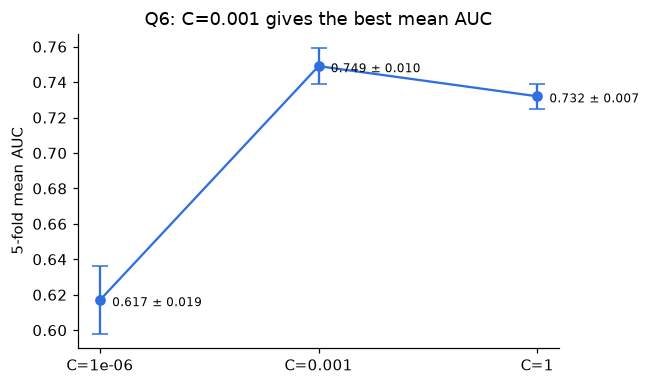

,C,mean_auc,std_auc
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007


In [9]:
cv = pd.DataFrame(res["c_results"], columns=["C", "mean_auc", "std_auc"])
print("Q5 fold scores:", np.round(res["cv_scores"], 4), " std =", round(res["cv_scores"].std(), 3))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(range(len(cv)), cv.mean_auc, yerr=cv.std_auc, fmt="o-", capsize=5, c="#2f6fdf")
ax.set_xticks(range(len(cv)), [f"C={c:g}" for c in cv.C])
for i, r in cv.iterrows(): ax.annotate(f"{r.mean_auc:.3f} ± {r.std_auc:.3f}", (i, r.mean_auc), xytext=(8, -4), textcoords="offset points", fontsize=8)
ax.set_ylabel("5-fold mean AUC"); ax.set_title("Q6: C=0.001 gives the best mean AUC")
plt.tight_layout(); plt.savefig("images/cv_by_c.png"); plt.show()
cv

## Answers

| # | Question | Answer |
|---|---|---|
| 1 | Highest single-feature AUC | `lead_score` (0.788) |
| 2 | Validation AUC | **0.732** |
| 3 | Precision = recall threshold | **0.63** |
| 4 | Max-F1 threshold | **0.41** |
| 5 | 5-fold CV std | **0.007** |
| 6 | Best C | **0.001** |